# Análise de sentimento da base IMDb com a `pipeline` do Hugging Face Transformers

Neste notebook eu uso a classe `pipeline` da biblioteca **transformers** para classificar o sentimento (positivo ou negativo) das resenhas de filmes da base **Large Movie Review Dataset (IMDb)**, de Maas et al. (2011), baixada diretamente do site da Universidade de Stanford.

Seguindo o capítulo [*Behind the pipeline*](https://huggingface.co/learn/nlp-course/chapter2/2?fw=pt) do curso de NLP do Hugging Face, além de usar a `pipeline` pronta, eu refaço manualmente as três etapas que ela executa (tokenização → modelo → pós-processamento) e confiro que os resultados são idênticos.

**Roteiro**

1. Download e leitura da base IMDb
2. Análise exploratória
3. Pré-processamento
4. A `pipeline` de análise de sentimento
5. Por dentro da `pipeline`: tokenizador, modelo e pós-processamento
6. Classificação das 25.000 resenhas de teste
7. Avaliação dos resultados
8. Resenhas longas: estratégias de truncamento
9. Comparações: modelo ajustado no IMDb e modelo clássico (TF-IDF + regressão logística)
10. Conclusões

In [1]:
import hashlib
import re
import tarfile
import time
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers
from transformers import AutoModel, AutoModelForSequenceClassification, AutoTokenizer, pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_colwidth', 200)

dispositivo = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'transformers {transformers.__version__} | PyTorch {torch.__version__} | dispositivo: {dispositivo}'
      + (f' ({torch.cuda.get_device_name(0)})' if dispositivo.type == 'cuda' else ''))

transformers 5.18.0 | PyTorch 2.11.0+cu130 | dispositivo: cuda (Tesla T4)


## 1. Download e leitura da base IMDb

A base tem 50.000 resenhas rotuladas (25.000 de treino e 25.000 de teste, metade positivas e metade negativas), além de 50.000 resenhas não rotuladas que não são usadas aqui. Segundo o README da base:

- uma resenha é **negativa** se a nota for ≤ 4 (de 10) e **positiva** se for ≥ 7; resenhas neutras (5 e 6) não foram incluídas;
- cada arquivo se chama `[id]_[nota].txt` e fica em `aclImdb/{train,test}/{pos,neg}/`;
- há no máximo 30 resenhas por filme, e os filmes do treino e do teste são diferentes.

O arquivo compactado (84 MB) é baixado uma única vez e conferido pelo hash MD5. Em vez de extrair os mais de 100 mil arquivos para o disco, as resenhas são lidas diretamente de dentro do `.tar.gz`.

In [2]:
URL_IMDB = 'https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz'
MD5_IMDB = '7c2ac02c03563afcf9b574c7e56c153a'
PASTA = Path('dados/imdb')
PASTA.mkdir(parents=True, exist_ok=True)
ARQUIVO = PASTA / 'aclImdb_v1.tar.gz'


def md5(caminho):
    h = hashlib.md5()
    with open(caminho, 'rb') as f:
        for bloco in iter(lambda: f.read(1 << 20), b''):
            h.update(bloco)
    return h.hexdigest()


if ARQUIVO.exists() and md5(ARQUIVO) == MD5_IMDB:
    print(f'{ARQUIVO} já baixado')
else:
    inicio = time.perf_counter()
    urllib.request.urlretrieve(URL_IMDB, ARQUIVO)
    print(f'Baixado em {time.perf_counter() - inicio:.0f} s')
print(f'Tamanho: {ARQUIVO.stat().st_size / 1e6:.1f} MB | MD5: {md5(ARQUIVO)} ({"ok" if md5(ARQUIVO) == MD5_IMDB else "DIFERENTE"})')

Baixado em 36 s
Tamanho: 84.1 MB | MD5: 7c2ac02c03563afcf9b574c7e56c153a (ok)


In [3]:
PADRAO = re.compile(r'aclImdb/(train|test)/(pos|neg)/(\d+)_(\d+)\.txt')

registros = []
with tarfile.open(ARQUIVO, 'r:gz') as tar:
    for membro in tar:
        correspondencia = PADRAO.fullmatch(membro.name)
        if correspondencia:
            conjunto, sentimento, id_, nota = correspondencia.groups()
            registros.append({
                'conjunto': 'treino' if conjunto == 'train' else 'teste',
                'id': int(id_),
                'nota': int(nota),
                'rotulo': 1 if sentimento == 'pos' else 0,
                'texto': tar.extractfile(membro).read().decode('utf-8'),
            })

imdb = pd.DataFrame(registros).sort_values(['conjunto', 'rotulo', 'id'], ascending=[False, True, True], ignore_index=True)
imdb['sentimento'] = imdb['rotulo'].map({0: 'negativo', 1: 'positivo'})
print(f'{len(imdb)} resenhas lidas')
imdb.head()

50000 resenhas lidas


,conjunto,id,nota,rotulo,texto,sentimento
0,treino,0,3,0,"Story of a man who has unnatural feelings for a pig. Starts out with a opening scene that is a terrific example of absurd comedy. A formal orchestra audience is turned into an insane, violent mob ...",negativo
1,treino,1,1,0,"Robert DeNiro plays the most unbelievably intelligent illiterate of all time. This movie is so wasteful of talent, it is truly disgusting. The script is unbelievable. The dialog is unbelievable. J...",negativo
2,treino,2,1,0,"I saw the capsule comment said ""great acting."" In my opinion, these are two great actors giving horrible performances, and with zero chemistry with one another, for a great director in his all-tim...",negativo
3,treino,3,4,0,"If I had not read Pat Barker's 'Union Street' before seeing this film, I would have liked it. Unfortuntately this is not the case. It is actually my kind of film, it is well made, and in no way do...",negativo
4,treino,4,4,0,This fanciful horror flick has Vincent Price playing a mad magician that realizes his vocational talents have been sold to another. He devise ways of avenging all those that have wronged him. His ...,negativo


## 2. Análise exploratória

sentimento,negativo,positivo,total
conjunto,,,
teste,12500,12500,25000
treino,12500,12500,25000
total,25000,25000,50000


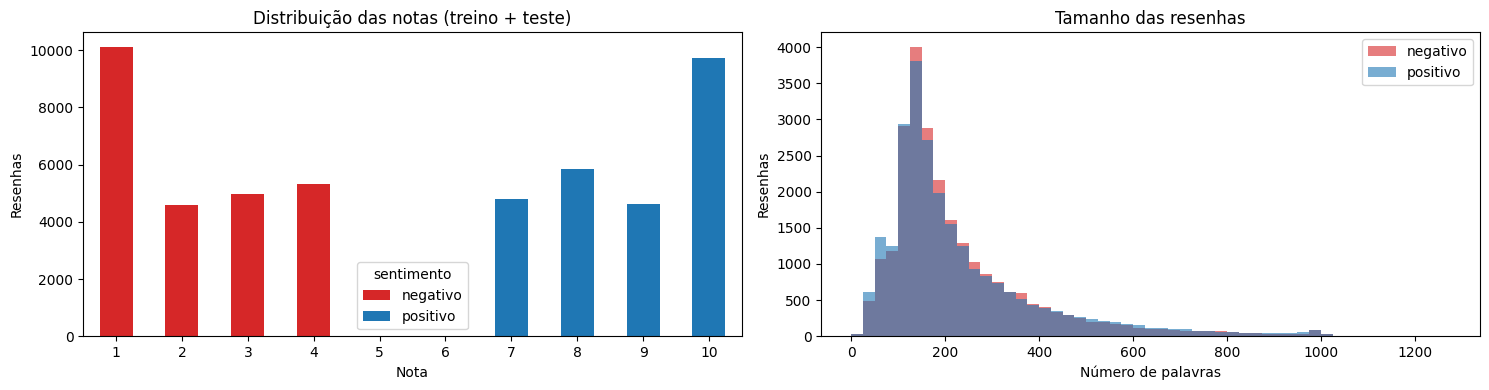

count    50000.0
mean       231.2
std        171.3
min          4.0
25%        126.0
50%        173.0
75%        280.0
max       2470.0


In [4]:
imdb['palavras'] = imdb['texto'].str.split().str.len()

display(pd.crosstab(imdb['conjunto'], imdb['sentimento'], margins=True, margins_name='total'))

fig, eixos = plt.subplots(1, 2, figsize=(15, 4))
contagem_notas = imdb.groupby(['nota', 'sentimento']).size().unstack(fill_value=0).reindex(range(1, 11), fill_value=0)
contagem_notas.plot.bar(ax=eixos[0], stacked=True, rot=0, color=['C3', 'C0'])
eixos[0].set(title='Distribuição das notas (treino + teste)', xlabel='Nota', ylabel='Resenhas')

for sentimento, cor in [('negativo', 'C3'), ('positivo', 'C0')]:
    eixos[1].hist(imdb.loc[imdb['sentimento'] == sentimento, 'palavras'], bins=np.arange(0, 1300, 25), alpha=0.6, color=cor, label=sentimento)
eixos[1].set(title='Tamanho das resenhas', xlabel='Número de palavras', ylabel='Resenhas')
eixos[1].legend()
plt.tight_layout()
plt.show()

print(imdb['palavras'].describe().round(1).to_string())

As classes são perfeitamente balanceadas em ambos os conjuntos, e as notas 5 e 6 não aparecem, como descrito no README. A maioria das resenhas tem entre 100 e 300 palavras, mas a distribuição tem uma cauda longa, com resenhas de mais de 1.000 palavras — isso será importante porque o modelo aceita no máximo 512 *tokens*.

Exemplo de resenha bruta:

In [5]:
exemplo = imdb.loc[imdb['texto'].str.contains('<br />')].iloc[0]
print(f"Nota {exemplo['nota']} ({exemplo['sentimento']}):\n")
print(exemplo['texto'])

Nota 1 (negativo):

Robert DeNiro plays the most unbelievably intelligent illiterate of all time. This movie is so wasteful of talent, it is truly disgusting. The script is unbelievable. The dialog is unbelievable. Jane Fonda's character is a caricature of herself, and not a funny one. The movie moves at a snail's pace, is photographed in an ill-advised manner, and is insufferably preachy. It also plugs in every cliche in the book. Swoozie Kurtz is excellent in a supporting role, but so what?<br /><br />Equally annoying is this new IMDB rule of requiring ten lines for every review. When a movie is this worthless, it doesn't require ten lines of text to let other readers know that it is a waste of time and tape. Avoid this movie.


## 3. Pré-processamento

O texto das resenhas veio de páginas HTML e contém marcações como `<br />` (quebras de linha). O pré-processamento consiste em:

1. remover as marcações HTML, substituindo-as por espaço;
2. normalizar os espaços em branco.

**O que não é necessário fazer** com um modelo Transformer, ao contrário dos métodos clássicos (bag-of-words): converter para minúsculas, remover *stopwords*, aplicar *stemming* ou remover pontuação. O tokenizador do modelo já faz a normalização que foi usada no pré-treinamento (o modelo é *uncased*, então ele mesmo converte para minúsculas), e palavras como "not" e a pontuação carregam informação de sentimento que o modelo sabe usar ("not good" ≠ "good"). Remover essas palavras alteraria o texto e prejudicaria o modelo.

In [6]:
TAG_HTML = re.compile(r'<[^>]+>')


def limpar(texto):
    return ' '.join(TAG_HTML.sub(' ', texto).split())


print('Resenhas com marcação HTML:', imdb['texto'].str.contains(TAG_HTML).sum())
imdb['texto_limpo'] = imdb['texto'].map(limpar)
print('Depois da limpeza:          ', imdb['texto_limpo'].str.contains(TAG_HTML).sum())
print()
print(exemplo['texto'][:300])
print('↓')
print(limpar(exemplo['texto'])[:300])

treino = imdb[imdb['conjunto'] == 'treino'].reset_index(drop=True)
teste = imdb[imdb['conjunto'] == 'teste'].reset_index(drop=True)

Resenhas com marcação HTML: 29202
Depois da limpeza:           0

Robert DeNiro plays the most unbelievably intelligent illiterate of all time. This movie is so wasteful of talent, it is truly disgusting. The script is unbelievable. The dialog is unbelievable. Jane Fonda's character is a caricature of herself, and not a funny one. The movie moves at a snail's pace
↓
Robert DeNiro plays the most unbelievably intelligent illiterate of all time. This movie is so wasteful of talent, it is truly disgusting. The script is unbelievable. The dialog is unbelievable. Jane Fonda's character is a caricature of herself, and not a funny one. The movie moves at a snail's pace


## 4. A `pipeline` de análise de sentimento

A `pipeline` é a forma mais simples de usar um modelo do Hugging Face: ela recebe texto e devolve o rótulo e a confiança. Para a tarefa `sentiment-analysis`, o modelo padrão é o [`distilbert-base-uncased-finetuned-sst-2-english`](https://huggingface.co/distilbert/distilbert-base-uncased-finetuned-sst-2-english), o mesmo usado no curso. Eu especifico o nome do modelo explicitamente para que o resultado seja reprodutível caso o padrão da biblioteca mude.

Sobre o modelo:

- **DistilBERT** é uma versão "destilada" do BERT, 40% menor e 60% mais rápida, que mantém ~97% do desempenho (Sanh et al., 2019). Tem 6 camadas Transformer e ~67 milhões de parâmetros.
- Ele foi ajustado (*fine-tuned*) no **SST-2** (Stanford Sentiment Treebank), um conjunto de frases curtas de críticas de cinema do site Rotten Tomatoes.
- Ou seja, o modelo **nunca viu a base IMDb**: estamos medindo o quanto um modelo de sentimento treinado em outro conjunto de críticas de cinema generaliza para resenhas mais longas e informais de usuários.

In [7]:
MODELO = 'distilbert/distilbert-base-uncased-finetuned-sst-2-english'
classificador = pipeline('sentiment-analysis', model=MODELO, device=dispositivo)

# Exemplos do curso
classificador([
    "I've been waiting for a HuggingFace course my whole life.",
    'I hate this so much!',
])

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

[{'label': 'POSITIVE', 'score': 0.9598046541213989},
 {'label': 'NEGATIVE', 'score': 0.9994558691978455}]

In [8]:
amostra = teste.sample(6, random_state=3)
saidas = classificador(amostra['texto_limpo'].tolist(), truncation=True)
pd.DataFrame({
    'resenha (início)': amostra['texto_limpo'].str[:150] + '...',
    'nota': amostra['nota'].values,
    'sentimento real': amostra['sentimento'].values,
    'previsão da pipeline': [s['label'] for s in saidas],
    'confiança': [round(s['score'], 4) for s in saidas],
})

,resenha (início),nota,sentimento real,previsão da pipeline,confiança
11758,"At least the jingle by Tim Finn was melodic. Roberts is the his usual inept self. Characters are inconsistent, dull, purposeless. Roberts changes his ...",1,negativo,NEGATIVE,0.9992
9342,"I'll not comment a lot, what's to??? Stereotype characters, absolute ignorance about Colombia's reality, awful mise en scene, poor color choice, NOT f...",1,negativo,NEGATIVE,0.9997
13245,... but you probably have seen it or else you wouldn't be here. It's so obscure that you probably stumbled onto it like I did because this little know...,10,positivo,POSITIVE,0.9937
10648,"After the failure of ""Hellraiser III: Hell On Earth,"" the chapter that served as a kind of 'death blow' to the franchise, another embarrassing cheapo ...",3,negativo,NEGATIVE,0.9990
15786,"Wesley Eure is young inventor Brian Foster, who's invented a new crime busting security device in the form of a robot dog, the titular ""C.H.O.M.P.S."" ...",7,positivo,POSITIVE,0.9991
15178,"Wow,this is in my opinion the best sitcom since Friends. If you have had a crap day just sit yourself down with a beer (if you are old enough that is....",10,positivo,POSITIVE,0.9984


## 5. Por dentro da `pipeline`

A `pipeline` executa três etapas:

```
texto  →  [tokenizador]  →  IDs dos tokens  →  [modelo]  →  logits  →  [pós-processamento]  →  rótulo + probabilidade
```

### 5.1 Tokenizador

O tokenizador divide o texto em *tokens* (palavras ou pedaços de palavras, pelo algoritmo WordPiece), adiciona os tokens especiais `[CLS]` (início) e `[SEP]` (fim) e converte cada token no seu índice no vocabulário. Com `padding=True` as sequências do lote são completadas com `[PAD]` até o mesmo tamanho, e a `attention_mask` indica quais posições são texto real (1) e quais são *padding* (0). Com `truncation=True`, textos maiores que o limite do modelo (512 tokens) são cortados.

In [9]:
tokenizador = AutoTokenizer.from_pretrained(MODELO)
frases = [
    "I've been waiting for a HuggingFace course my whole life.",
    'I hate this so much!',
]
entradas = tokenizador(frases, padding=True, truncation=True, return_tensors='pt')
print('Chaves:', list(entradas.keys()))
print('input_ids:\n', entradas['input_ids'])
print('attention_mask:\n', entradas['attention_mask'])
print()
for ids in entradas['input_ids']:
    print(tokenizador.convert_ids_to_tokens(ids))
print(f'\nTamanho do vocabulário: {tokenizador.vocab_size} | comprimento máximo: {tokenizador.model_max_length} tokens')

Chaves: ['input_ids', 'token_type_ids', 'attention_mask']
input_ids:
 tensor([[  101,  1045,  1005,  2310,  2042,  3403,  2005,  1037, 17662, 12172,
          2607,  2026,  2878,  2166,  1012,   102],
        [  101,  1045,  5223,  2023,  2061,  2172,   999,   102,     0,     0,
             0,     0,     0,     0,     0,     0]])
attention_mask:
 tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0]])

['[CLS]', 'i', "'", 've', 'been', 'waiting', 'for', 'a', 'hugging', '##face', 'course', 'my', 'whole', 'life', '.', '[SEP]']
['[CLS]', 'i', 'hate', 'this', 'so', 'much', '!', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']

Tamanho do vocabulário: 30522 | comprimento máximo: 512 tokens


### 5.2 Modelo

O modelo base (`AutoModel`) devolve, para cada token, um vetor de 768 dimensões (o *hidden state* da última camada), com formato `(lote, tokens, 768)`.

O modelo com "cabeça" de classificação (`AutoModelForSequenceClassification`) acrescenta uma camada linear sobre o vetor do token `[CLS]` e devolve um **logit** por classe, com formato `(lote, 2)`. Os logits são valores não normalizados.

In [10]:
modelo_base = AutoModel.from_pretrained(MODELO)
with torch.no_grad():
    saida_base = modelo_base(**entradas)
print('AutoModel -> last_hidden_state:', tuple(saida_base.last_hidden_state.shape))

modelo = AutoModelForSequenceClassification.from_pretrained(MODELO)
modelo.eval()
with torch.no_grad():
    logits = modelo(**entradas).logits
print('AutoModelForSequenceClassification -> logits:', tuple(logits.shape))
print(logits)
print(f'\nParâmetros do modelo: {sum(p.numel() for p in modelo.parameters()) / 1e6:.1f} milhões')

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

AutoModel -> last_hidden_state: (2, 16, 768)


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

AutoModelForSequenceClassification -> logits: (2, 2)
tensor([[-1.5607,  1.6123],
        [ 4.1692, -3.3464]])

Parâmetros do modelo: 67.0 milhões


### 5.3 Pós-processamento

Os logits são convertidos em probabilidades pela função **softmax**, $p_k = e^{z_k} / \sum_j e^{z_j}$, e o índice da maior probabilidade é traduzido para o nome da classe por `model.config.id2label`.

In [11]:
probabilidades = torch.softmax(logits, dim=-1)
print('Probabilidades:\n', probabilidades)
print('id2label:', modelo.config.id2label)
print()

saida_pipeline = classificador(frases)
for frase, p, s in zip(frases, probabilidades, saida_pipeline):
    k = int(p.argmax())
    print(f'{frase!r}')
    print(f'   manual:   {modelo.config.id2label[k]} ({p[k]:.6f})')
    print(f'   pipeline: {s["label"]} ({s["score"]:.6f})')

Probabilidades:
 tensor([[4.0195e-02, 9.5980e-01],
        [9.9946e-01, 5.4418e-04]])
id2label: {0: 'NEGATIVE', 1: 'POSITIVE'}

"I've been waiting for a HuggingFace course my whole life."
   manual:   POSITIVE (0.959805)
   pipeline: POSITIVE (0.959805)
'I hate this so much!'
   manual:   NEGATIVE (0.999456)
   pipeline: NEGATIVE (0.999456)


Conferindo nas mesmas 6 resenhas do IMDb usadas acima (com truncamento em 512 tokens) que as três etapas manuais reproduzem exatamente a `pipeline`:

In [12]:
entradas_imdb = tokenizador(amostra['texto_limpo'].tolist(), padding=True, truncation=True, return_tensors='pt')
with torch.no_grad():
    probs_manual = torch.softmax(modelo(**entradas_imdb).logits, dim=-1).numpy()
rotulos_manual = [modelo.config.id2label[k] for k in probs_manual.argmax(axis=1)]
scores_manual = probs_manual.max(axis=1)
print('Rótulos iguais:', rotulos_manual == [s['label'] for s in saidas])
print('Maior diferença nas probabilidades:', np.abs(scores_manual - np.array([s['score'] for s in saidas])).max())
del modelo_base, modelo

Rótulos iguais: True
Maior diferença nas probabilidades: 0.0


## 6. Classificação das 25.000 resenhas de teste

Agora a `pipeline` é aplicada a todo o conjunto de teste. Alguns cuidados:

- **`truncation=True`**: resenhas com mais de 512 tokens são cortadas, mantendo o início (a seção 8 analisa o impacto disso).
- **Lotes ordenados por tamanho**: a `pipeline` completa cada lote com *padding* até a maior resenha do lote. Ordenando as resenhas por tamanho, cada lote tem resenhas de tamanho parecido e quase não há processamento desperdiçado.
- As previsões são salvas em disco para não precisar refazer a inferência a cada execução do notebook.

In [13]:
def classificar(clf, textos, tamanho_lote=16, **kwargs):
    """Aplica a pipeline a uma lista de textos e devolve a probabilidade da classe positiva."""
    rotulo_positivo = clf.model.config.id2label[1]
    ordem = np.argsort([len(t) for t in textos])[::-1]  # maiores primeiro
    prob_positivo = np.empty(len(textos))
    inicio = time.perf_counter()
    saidas = clf((textos[i] for i in ordem), batch_size=tamanho_lote, truncation=True, **kwargs)
    for k, (i, saida) in enumerate(zip(ordem, saidas), start=1):
        prob_positivo[i] = saida['score'] if saida['label'] == rotulo_positivo else 1 - saida['score']
        if k % 5000 == 0 or k == len(textos):
            print(f'  {k:>6}/{len(textos)} resenhas | {time.perf_counter() - inicio:6.0f} s')
    return prob_positivo


def classificar_com_cache(nome_arquivo, clf, textos, **kwargs):
    caminho = PASTA / nome_arquivo
    if caminho.exists():
        print(f'Carregando previsões salvas em {caminho}')
        return np.load(caminho)
    prob = classificar(clf, textos, **kwargs)
    np.save(caminho, prob)
    return prob


teste['prob_positivo'] = classificar_com_cache('previsoes_distilbert_sst2.npy', classificador, teste['texto_limpo'].tolist())
teste['previsao'] = (teste['prob_positivo'] >= 0.5).astype(int)
teste['confianca'] = np.maximum(teste['prob_positivo'], 1 - teste['prob_positivo'])
teste['acertou'] = teste['previsao'] == teste['rotulo']

    5000/25000 resenhas |     83 s
   10000/25000 resenhas |    140 s
   15000/25000 resenhas |    178 s
   20000/25000 resenhas |    208 s
   25000/25000 resenhas |    228 s


## 7. Avaliação dos resultados

Acurácia no teste: 0.8923

              precision    recall  f1-score   support

    negativo     0.8718    0.9198    0.8952     12500
    positivo     0.9151    0.8648    0.8892     12500

    accuracy                         0.8923     25000
   macro avg     0.8935    0.8923    0.8922     25000
weighted avg     0.8935    0.8923    0.8922     25000



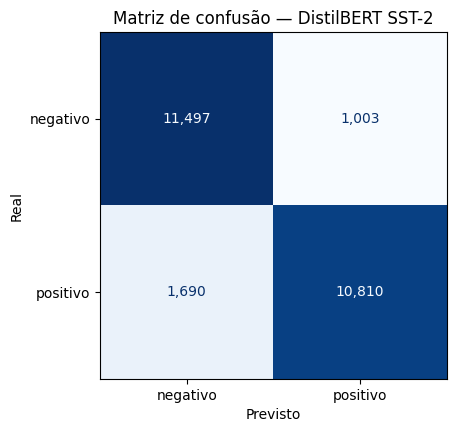

In [14]:
print(f"Acurácia no teste: {accuracy_score(teste['rotulo'], teste['previsao']):.4f}\n")
print(classification_report(teste['rotulo'], teste['previsao'], target_names=['negativo', 'positivo'], digits=4))

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(teste['sentimento'], teste['previsao'].map({0: 'negativo', 1: 'positivo'}),
                                        ax=ax, cmap='Blues', colorbar=False, values_format=',')
ax.set(title='Matriz de confusão — DistilBERT SST-2', xlabel='Previsto', ylabel='Real')
plt.show()

### Acurácia por nota, por tamanho e por confiança

Para entender **onde** o modelo erra, a acurácia é separada pela nota original da resenha, pelo tamanho em tokens e pela confiança da previsão.

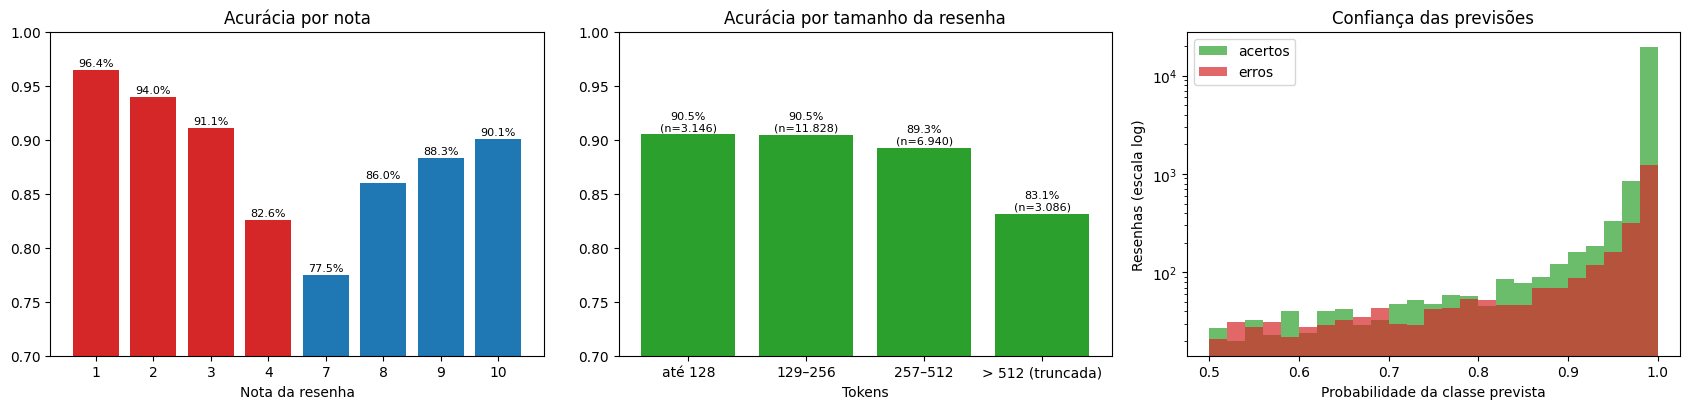

Resenhas com mais de 512 tokens: 12.3%
Confiança ≥ 0.9: 92.9% das resenhas, acurácia 91.77%
Confiança ≥ 0.99: 77.0% das resenhas, acurácia 95.66%


In [15]:
teste['tokens'] = [len(ids) for ids in tokenizador(teste['texto_limpo'].tolist())['input_ids']]
faixas = [0, 128, 256, 512, np.inf]
nomes_faixas = ['até 128', '129–256', '257–512', '> 512 (truncada)']
teste['faixa_tokens'] = pd.cut(teste['tokens'], faixas, labels=nomes_faixas)

fig, eixos = plt.subplots(1, 3, figsize=(17, 4.2))

por_nota = teste.groupby('nota')['acertou'].mean()
eixos[0].bar(por_nota.index.astype(str), por_nota, color=['C3'] * 4 + ['C0'] * 4)
eixos[0].set(title='Acurácia por nota', xlabel='Nota da resenha', ylim=(0.7, 1))
for x, y in zip(range(len(por_nota)), por_nota):
    eixos[0].text(x, y + 0.004, f'{y:.1%}', ha='center', fontsize=8)

por_faixa = teste.groupby('faixa_tokens', observed=True)['acertou'].agg(['mean', 'size'])
eixos[1].bar(por_faixa.index.astype(str), por_faixa['mean'], color='C2')
eixos[1].set(title='Acurácia por tamanho da resenha', xlabel='Tokens', ylim=(0.7, 1))
for x, (m, n) in enumerate(por_faixa.values):
    eixos[1].text(x, m + 0.004, f'{m:.1%}\n(n={int(n):,})'.replace(',', '.'), ha='center', fontsize=8)

bins = np.linspace(0.5, 1, 26)
eixos[2].hist(teste.loc[teste['acertou'], 'confianca'], bins=bins, alpha=0.7, label='acertos', color='C2', log=True)
eixos[2].hist(teste.loc[~teste['acertou'], 'confianca'], bins=bins, alpha=0.7, label='erros', color='C3', log=True)
eixos[2].set(title='Confiança das previsões', xlabel='Probabilidade da classe prevista', ylabel='Resenhas (escala log)')
eixos[2].legend()
plt.tight_layout()
plt.show()

print(f"Resenhas com mais de 512 tokens: {np.mean(teste['tokens'] > 512):.1%}")
for limite in [0.9, 0.99]:
    sel = teste['confianca'] >= limite
    print(f'Confiança ≥ {limite}: {sel.mean():.1%} das resenhas, acurácia {teste.loc[sel, "acertou"].mean():.2%}')

### Exemplos de erros

As resenhas abaixo são os erros em que o modelo estava **mais confiante**. Elas ajudam a entender as limitações: ironia, resenhas que descrevem longamente o enredo antes de dar a opinião, e opiniões mistas ("ótimas atuações, mas roteiro fraco").

In [16]:
for rotulo_real in [0, 1]:
    erros = teste[(teste['rotulo'] == rotulo_real) & ~teste['acertou']].nlargest(3, 'confianca')
    print('=' * 100)
    print(f"Resenhas {'NEGATIVAS classificadas como POSITIVAS' if rotulo_real == 0 else 'POSITIVAS classificadas como NEGATIVAS'}")
    print('=' * 100)
    for _, linha in erros.iterrows():
        print(f"[nota {linha['nota']}, confiança {linha['confianca']:.4f}] {linha['texto_limpo'][:700]}{'...' if len(linha['texto_limpo']) > 700 else ''}\n")

Resenhas NEGATIVAS classificadas como POSITIVAS
[nota 4, confiança 0.9999] I really liked this quirky movie. The characters are not the bland beautiful people that show up in so many movies and on TV. It has a realistic edge, with a captivating story line. The main title sequence alone makes this movie fun to watch.

[nota 1, confiança 0.9999] This movie was pure genius. John Waters is brilliant. It is hilarious and I am not sick of it even after seeing it about 20 times since I bought it a few months ago. The acting is great, although Ricki Lake could have been better. And Johnny Depp is magnificent. He is such a beautiful man and a very talented actor. And seeing most of Johnny's movies, this is probably my favorite. I give it 9.5/10. Rent it today!

[nota 1, confiança 0.9999] This is definitely one of the best Kung fu movies in the history of Cinema. The screenplay is really well done (which is not often the case for this type of movies) and you can see that Chuck (in one of his fir

## 8. Resenhas longas: estratégias de truncamento

O DistilBERT processa no máximo 512 tokens. Por padrão a `pipeline` mantém o **início** do texto e descarta o resto, mas em resenhas é comum que a opinião final apareça no **fim** ("...enfim, recomendo"). Sun et al. (2019), *How to Fine-Tune BERT for Text Classification?*, compararam estratégias de truncamento justamente no IMDb e encontraram melhores resultados combinando o início e o fim do texto.

Comparo três estratégias nas resenhas de teste com mais de 512 tokens:

- **início**: os primeiros 510 tokens (padrão);
- **fim**: os últimos 510 tokens;
- **início + fim**: os primeiros 128 e os últimos 382 tokens (melhor combinação no artigo).

O texto truncado é reconstruído com o próprio tokenizador (`decode`) e passado para a `pipeline`.

In [17]:
longas = teste[teste['tokens'] > 512].copy()
ids_longas = tokenizador(longas['texto_limpo'].tolist(), add_special_tokens=False)['input_ids']
estrategias = {
    'início': lambda ids: ids[:510],
    'fim': lambda ids: ids[-510:],
    'início + fim': lambda ids: ids[:128] + ids[-382:],
}

resultado_truncamento = []
for nome, cortar in estrategias.items():
    if nome == 'início':
        prob = longas['prob_positivo'].values  # já calculado na seção 6
    else:
        print(f'Estratégia "{nome}":')
        textos = tokenizador.batch_decode([cortar(ids) for ids in ids_longas])
        arquivo = f"previsoes_longas_{nome.replace(' + ', '_').replace('í', 'i')}.npy"
        prob = classificar_com_cache(arquivo, classificador, textos)
    resultado_truncamento.append({'Estratégia': nome, 'Acurácia nas resenhas longas': np.mean((prob >= 0.5) == longas['rotulo'])})
    longas[f'prob_{nome}'] = prob

print(f'\n{len(longas):,} resenhas com mais de 512 tokens'.replace(',', '.'))
pd.DataFrame(resultado_truncamento).set_index('Estratégia').round(4)

Estratégia "fim":
    3086/3086 resenhas |     52 s
Estratégia "início + fim":
    3086/3086 resenhas |     51 s

3.086 resenhas com mais de 512 tokens


,Acurácia nas resenhas longas
Estratégia,
início,0.8312
fim,0.8561
início + fim,0.8600


In [18]:
melhor = max(resultado_truncamento, key=lambda r: r['Acurácia nas resenhas longas'])['Estratégia']
teste['prob_melhor_truncamento'] = teste['prob_positivo']
teste.loc[longas.index, 'prob_melhor_truncamento'] = longas[f'prob_{melhor}']
acc_antes = accuracy_score(teste['rotulo'], teste['prob_positivo'] >= 0.5)
acc_depois = accuracy_score(teste['rotulo'], teste['prob_melhor_truncamento'] >= 0.5)
print(f'Acurácia no teste completo — truncamento padrão (início): {acc_antes:.4f}')
print(f'Acurácia no teste completo — estratégia "{melhor}" nas resenhas longas: {acc_depois:.4f}')

Acurácia no teste completo — truncamento padrão (início): 0.8923
Acurácia no teste completo — estratégia "início + fim" nas resenhas longas: 0.8958


## 9. Comparações

Para colocar o resultado em perspectiva, comparo o modelo da `pipeline` com duas alternativas:

1. **Modelo clássico supervisionado**: TF-IDF (unigramas e bigramas) + regressão logística, **treinado nas 25.000 resenhas de treino** do próprio IMDb. É um *baseline* forte e muito usado para essa base.
2. **Transformer ajustado no IMDb**: a mesma `pipeline`, mas com um DistilBERT que foi ajustado (*fine-tuned*) no conjunto de treino do IMDb ([`lvwerra/distilbert-imdb`](https://huggingface.co/lvwerra/distilbert-imdb)). Assim dá para separar o efeito da arquitetura do efeito de ter sido treinado em dados do mesmo domínio.

Os dois usam apenas o conjunto de treino para aprender, e todos são avaliados no mesmo conjunto de teste.

In [19]:
inicio = time.perf_counter()
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9, sublinear_tf=True)
X_treino_tfidf = tfidf.fit_transform(treino['texto_limpo'])
X_teste_tfidf = tfidf.transform(teste['texto_limpo'])
regressao = LogisticRegression(C=10, max_iter=2000).fit(X_treino_tfidf, treino['rotulo'])
teste['prob_tfidf'] = regressao.predict_proba(X_teste_tfidf)[:, 1]
print(f'TF-IDF: {X_treino_tfidf.shape[1]:,} atributos | treino + previsão em {time.perf_counter() - inicio:.0f} s'.replace(',', '.'))

TF-IDF: 436.584 atributos | treino + previsão em 23 s


In [20]:
MODELO_IMDB = 'lvwerra/distilbert-imdb'
classificador_imdb = pipeline('sentiment-analysis', model=MODELO_IMDB, device=dispositivo)
print('Rótulos do modelo:', classificador_imdb.model.config.id2label)
teste['prob_imdb'] = classificar_com_cache('previsoes_distilbert_imdb.npy', classificador_imdb, teste['texto_limpo'].tolist())

config.json:   0%|          | 0.00/735 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  268MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/333 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Rótulos do modelo: {0: 'NEGATIVE', 1: 'POSITIVE'}
    5000/25000 resenhas |     82 s
   10000/25000 resenhas |    137 s
   15000/25000 resenhas |    175 s
   20000/25000 resenhas |    204 s
   25000/25000 resenhas |    223 s


In [21]:
modelos_comparados = {
    'TF-IDF + regressão logística (treinado no IMDb)': 'prob_tfidf',
    'DistilBERT SST-2 — pipeline padrão (não viu o IMDb)': 'prob_positivo',
    f'DistilBERT SST-2 — truncamento "{melhor}"': 'prob_melhor_truncamento',
    'DistilBERT ajustado no IMDb (lvwerra/distilbert-imdb)': 'prob_imdb',
}
linhas = []
for nome, coluna in modelos_comparados.items():
    previsao = (teste[coluna] >= 0.5).astype(int)
    relatorio = classification_report(teste['rotulo'], previsao, output_dict=True)
    linhas.append({
        'Modelo': nome,
        'Acurácia': relatorio['accuracy'],
        'F1 negativo': relatorio['0']['f1-score'],
        'F1 positivo': relatorio['1']['f1-score'],
        'Erros (de 25.000)': int((previsao != teste['rotulo']).sum()),
    })
pd.DataFrame(linhas).set_index('Modelo').round(4)

,Acurácia,F1 negativo,F1 positivo,Erros (de 25.000)
Modelo,,,,
TF-IDF + regressão logística (treinado no IMDb),0.9062,0.9060,0.9063,2346
DistilBERT SST-2 — pipeline padrão (não viu o IMDb),0.8923,0.8952,0.8892,2693
"DistilBERT SST-2 — truncamento ""início + fim""",0.8958,0.8983,0.8933,2604
DistilBERT ajustado no IMDb (lvwerra/distilbert-imdb),0.9284,0.9285,0.9284,1789


## 10. Conclusões

CONCLUSOES